# ☀️ Photovoltaic Panel 1: Expected Power & Digital Twin (TensorFlow / Keras ANN)
### Model Target: Expected Power ($P_1$) using Environmental Telemetry ($Irr$ and $T_1$) with a Deep TensorFlow ANN

---

### 📋 Overview & Methodology:
1. **Environmental Inputs Only**: Strictly Solar Irradiance (`Irr`) [W/m²] and Panel Temperature (`T1`) [°C].
   - *Digital Twin Concept*: We explicitly exclude electrical signals ($V_1, I_1$) from inputs because under faults (degradation, shading, open/short circuits) voltage and current drop drastically. The Expected Power reflects what a **healthy PV panel ought to generate** under current atmospheric conditions.
2. **Physics-Informed Feature Engineering**:
   - Interaction term: $Irr \times T_1$
   - Quadratic non-linearities: $Irr^2$, $T_1^2$
   - Silicon temperature derating: $Irr \times (1 - 0.0045 \times (T_1 - 25.0))$ (standard silicon PV thermal derating)
   - Irradiance per Kelvin: $Irr / (T_1 + 273.15)$
3. **TensorFlow / Keras Deep ANN Architecture**:
   - **Input Layer**: 7 physics-informed features
   - **StandardScaler**: Feature normalization for optimal gradient descent
   - **Dense Layer 1**: 64 neurons, ReLU activation, L2 weight regularization ($10^{-4}$)
   - **Batch Normalization & Dropout (5%)**: Stabilizes internal covariance shift and prevents co-adaptation
   - **Dense Layer 2**: 64 neurons, ReLU activation, L2 weight regularization ($10^{-4}$)
   - **Batch Normalization & Dropout (5%)**
   - **Dense Layer 3**: 32 neurons, ReLU activation
   - **Output Layer**: 1 neuron with ReLU activation (ensures physically valid non-negative power output)
   - **Optimizer**: Adam with learning rate scheduling (`ReduceLROnPlateau`) and early stopping (`EarlyStopping`)
4. **Training Exclusively on Healthy Baseline**:
   - Model trained on active healthy daytime conditions (`Label_S1 == 'Normal'` and $V_1 \ge 5.0\text{V}$).
5. **Residual-Based Fault Detection Across Anomalies**:
   - Validated on unseen **Normal** data alongside all **Anomalies** (`Degradation`, `Shading`, `Open Circuit`, `Short Circuit`).
   - Computes **Residual Power Loss** ($\Delta P = P_{1,\text{expected}} - P_{1,\text{actual}}$) and **Performance Ratio ($PR\%$)**.


In [1]:
import os
import sys
from pathlib import Path

# Ensure UTF-8 output encoding across environments
if hasattr(sys.stdout, 'reconfigure'):
    sys.stdout.reconfigure(encoding='utf-8')

# Suppress TensorFlow INFO logs
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import joblib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks, regularizers

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)

print("Environment and libraries loaded successfully.")
print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version: {keras.__version__}")


Environment and libraries loaded successfully.
TensorFlow Version: 2.21.0
Keras Version: 3.12.4


## 1. Feature Engineering (Strictly using `Irr` and `T1`)
Derives non-linear, interaction, and thermodynamic temperature derating terms strictly from solar irradiance and panel temperature.


In [2]:
def extract_pv_features(df_input: pd.DataFrame) -> pd.DataFrame:
    """
    Extracts features for Expected Power prediction using ONLY Irradiance and Temperature.
    
    Includes:
    - Raw Irradiance (Irr) [W/m^2]
    - Raw Panel Temperature (T1) [deg C]
    - Interaction term: Irr * T1
    - Non-linear terms: Irr^2, T1^2
    - Temperature-derated effective irradiance: Irr * (1 - 0.0045 * (T1 - 25))
    - Temperature ratio in Kelvin: Irr / (T1 + 273.15)
    """
    X = pd.DataFrame(index=df_input.index)
    irr = df_input['Irr'].astype(float)
    t1 = df_input['T1'].astype(float)
    
    X['Irr'] = irr
    X['T1'] = t1
    X['Irr_T1_interaction'] = irr * t1
    X['Irr_squared'] = irr ** 2
    X['T1_squared'] = t1 ** 2
    
    # Standard silicon PV temperature coefficient derating (-0.45% / deg C from 25 deg C)
    X['Irr_temp_derated'] = irr * (1.0 - 0.0045 * (t1 - 25.0))
    X['Irr_per_Kelvin'] = irr / (t1 + 273.15)
    
    return X


## 2. Load Dataset and Daylight Telemetry
Loads `PV_Diagnostic_Cleaned.csv`, isolates active daylight records ($Irr \ge 50\text{ W/m}^2$), and creates training and combined anomaly testing sets.


In [3]:
def load_and_prepare_dataset(csv_path: str):
    """
    Loads dataset, isolates active daytime telemetry, and creates train/test splits.
    """
    print(f"Loading dataset from: {csv_path}")
    df = pd.read_csv(csv_path, sep=';')
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    
    # Filter daylight hours (Irr >= 50 W/m^2) where PV power generation is active
    day_df = df[df['Irr'] >= 50.0].copy().reset_index(drop=True)
    print(f"Total records: {len(df):,} | Daytime records (Irr >= 50 W/m²): {len(day_df):,}")
    
    # Normal active generation condition (Panel healthy and producing power)
    normal_mask = (day_df['Label_S1'] == 'Normal') & (day_df['V1'] >= 5.0)
    normal_df = day_df[normal_mask].copy()
    anomaly_df = day_df[day_df['Label_S1'] != 'Normal'].copy()
    
    # 80/20 train/test split on NORMAL data
    norm_train_df, norm_test_df = train_test_split(
        normal_df, test_size=0.20, random_state=42
    )
    
    # Combined Test Set containing BOTH unseen Normal states and Anomalies
    test_combined_df = pd.concat([norm_test_df, anomaly_df], axis=0).reset_index(drop=True)
    
    print(f"\n--- Split Summary ---")
    print(f"Training set (Normal Active only)     : {len(norm_train_df):,} samples")
    print(f"Test set (Unseen Normal + Anomalies) : {len(test_combined_df):,} samples")
    print(f"  - Unseen Normal samples in test     : {len(norm_test_df):,} samples")
    print(f"  - Anomalous samples in test         : {len(anomaly_df):,} samples")
    
    return norm_train_df, norm_test_df, test_combined_df, day_df

# Candidate paths detection
candidates = [
    Path("data/PV_Diagnostic_Cleaned.csv"),
    Path("../data/PV_Diagnostic_Cleaned.csv"),
    Path(r"C:\Users\kirok\Desktop\New folder (7)\data\PV_Diagnostic_Cleaned.csv"),
]
dataset_file = next((str(p) for p in candidates if p.exists()), None)
if dataset_file is None:
    raise FileNotFoundError("Could not find PV_Diagnostic_Cleaned.csv")

train_norm, test_norm, test_combined, full_day = load_and_prepare_dataset(dataset_file)


Loading dataset from: data\PV_Diagnostic_Cleaned.csv
Total records: 226,175 | Daytime records (Irr >= 50 W/m²): 221,190

--- Split Summary ---
Training set (Normal Active only)     : 31,639 samples
Test set (Unseen Normal + Anomalies) : 182,580 samples
  - Unseen Normal samples in test     : 7,910 samples
  - Anomalous samples in test         : 174,670 samples


## 3. Train TensorFlow / Keras Deep ANN on Healthy Baseline Telemetry
We define and train a **Deep Multi-Layer Perceptron (ANN)** in **TensorFlow / Keras**:
- **Feature Scaling**: `StandardScaler` standardizes features to zero mean and unit variance.
- **Batch Normalization & Dropout**: Mitigates internal covariate shift and prevents overfitting.
- **Epoch-by-Epoch Progress**: Explicitly prints each training epoch with loss, MAE, validation metrics, and learning rate adjustment.
- **Early Stopping**: Restores best weights when validation loss stabilizes.


In [4]:
import time
def build_and_train_tf_ann(train_df: pd.DataFrame, val_df: pd.DataFrame):
    """
    Prepares features with StandardScaler and trains a TensorFlow Keras ANN.
    """
    X_train = extract_pv_features(train_df)
    y_train = train_df['P1'].astype(float).values
    
    X_val = extract_pv_features(val_df)
    y_val = val_df['P1'].astype(float).values
    
    # Fit scaler on training set
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    print("Building TensorFlow / Keras ANN Architecture...")
    model = keras.Sequential([
        layers.Input(shape=(X_train_scaled.shape[1],)),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="dense_1"),
        layers.BatchNormalization(name="batch_norm_1"),
        layers.Dropout(0.05, name="dropout_1"),
        layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="dense_2"),
        layers.BatchNormalization(name="batch_norm_2"),
        layers.Dropout(0.05, name="dropout_2"),
        layers.Dense(64, activation='relu', name="dense_3"),
        layers.Dense(1, activation='relu', name="output_power")
    ], name="PV_Expected_Power_ANN_TF")
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.008),
        loss='mse',
        metrics=['mae', 'root_mean_squared_error']
    )
    model.summary()
    
    # Callbacks
    class EpochProgressCallback(callbacks.Callback):
        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            lr = float(self.model.optimizer.learning_rate.numpy())
            print(f"Epoch {epoch+1:2d}/100 - loss: {logs.get('loss', 0):.2f} - mae: {logs.get('mae', 0):.2f} W "
                  f"- val_loss: {logs.get('val_loss', 0):.2f} - val_mae: {logs.get('val_mae', 0):.2f} W - lr: {lr:.5f}")
    
    es_callback = callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=0)
    lr_callback = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=0)
    
    print("\nStarting TensorFlow ANN Training across Epochs:")
    t0 = time.time()
    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=128,
        verbose=0,
        callbacks=[EpochProgressCallback(), es_callback, lr_callback]
    )
    t_train = time.time() - t0
    print(f"\nTraining completed in {t_train:.2f} seconds.")
    
    # Validation evaluation
    y_pred_val = np.maximum(0.0, model.predict(X_val_scaled, verbose=0).flatten())
    r2 = r2_score(y_val, y_pred_val)
    mae = mean_absolute_error(y_val, y_pred_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    
    print("\n=======================================================")
    print("  TensorFlow ANN Performance on Unseen Normal Test Data")
    print("=======================================================")
    print(f"  R² Score (Coefficient of Determination) : {r2:.4f}")
    print(f"  Mean Absolute Error (MAE)               : {mae:.2f} Watts")
    print(f"  Root Mean Squared Error (RMSE)          : {rmse:.2f} Watts")
    print("=======================================================\n")
    
    return model, scaler, history

tf_model, scaler, history = build_and_train_tf_ann(train_norm, test_norm)

# Save model and scaler artifacts
models_dir = Path("../models") if Path("../models").exists() else Path("models")
models_dir.mkdir(parents=True, exist_ok=True)
model_path_keras = models_dir / "pv_expected_power_p1_tf_ann.keras"
scaler_path = models_dir / "pv_expected_power_scaler_tf.pkl"

tf_model.save(model_path_keras)
joblib.dump(scaler, scaler_path)
print(f"Model artifact saved to: {model_path_keras}")
print(f"Scaler artifact saved to: {scaler_path}")


Building TensorFlow / Keras ANN Architecture...


Model: "PV_Expected_Power_ANN_TF"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_power (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,881 (105.00 KB)

 Trainable params: 26,369 (103.00 KB)

 Non-trainable params: 512 (2.00 KB)


Starting TensorFlow ANN Training across Epochs:
Epoch  1/100 - loss: 451.54 - mae: 12.42 W - val_loss: 489.20 - val_mae: 12.41 W - lr: 0.00800
Epoch  2/100 - loss: 318.02 - mae: 10.03 W - val_loss: 348.36 - val_mae: 9.71 W - lr: 0.00800
Epoch  3/100 - loss: 295.28 - mae: 9.29 W - val_loss: 318.24 - val_mae: 9.44 W - lr: 0.00800
Epoch  4/100 - loss: 278.70 - mae: 8.81 W - val_loss: 263.15 - val_mae: 8.07 W - lr: 0.00800
Epoch  5/100 - loss: 276.63 - mae: 8.75 W - val_loss: 252.31 - val_mae: 7.94 W - lr: 0.00800
Epoch  6/100 - loss: 267.18 - mae: 8.58 W - val_loss: 264.67 - val_mae: 7.59 W - lr: 0.00800
Epoch  7/100 - loss: 271.31 - mae: 8.60 W - val_loss: 325.75 - val_mae: 10.09 W - lr: 0.00800
Epoch  8/100 - loss: 269.67 - mae: 8.55 W - val_loss: 272.21 - val_mae: 8.05 W - lr: 0.00800
Epoch  9/100 - loss: 269.24 - mae: 8.39 W - val_loss: 362.10 - val_mae: 8.69 W - lr: 0.00800
Epoch 10/100 - loss: 257.83 - mae: 8.09 W - val_loss: 225.57 - val_mae: 7.07 W - lr: 0.00400
Epoch 11/100 - lo

## 4. Interactive Prediction: Pass `(Irr, T1)` -> Predict Expected Power
Function to predict expected healthy power from arbitrary solar irradiance ($W/m^2$) and temperature ($^\circ\text{C}$) using the TensorFlow model.


In [5]:
def predict_expected_power(model, scaler, irradiance: float, temperature: float) -> float:
    """
    Given single values of Irradiance (W/m^2) and Temperature (deg C),
    predicts the expected healthy power (Watts) for Panel 1 using TensorFlow ANN.
    """
    sample_df = pd.DataFrame({'Irr': [irradiance], 'T1': [temperature]})
    X_sample = extract_pv_features(sample_df)
    X_sample_scaled = scaler.transform(X_sample)
    expected_p = float(model.predict(X_sample_scaled, verbose=0)[0][0])
    return max(0.0, expected_p)

# Interactive demonstration across realistic weather conditions
demo_scenarios = [
    {"Irr": 200.0, "T1": 25.0, "desc": "Low morning sunlight, cool panel"},
    {"Irr": 600.0, "T1": 38.0, "desc": "Moderate midday sunlight, warm panel"},
    {"Irr": 850.0, "T1": 42.0, "desc": "Strong afternoon sunlight, hot panel"},
    {"Irr": 1000.0, "T1": 45.0, "desc": "Peak STC irradiance, high temperature"}
]

print("--- Example Predictions: See (Irr, T1) -> Expected Power ---")
for sc in demo_scenarios:
    p_exp = predict_expected_power(tf_model, scaler, sc['Irr'], sc['T1'])
    print(f"  • {sc['desc']}:")
    print(f"    Irr = {sc['Irr']:>6.1f} W/m², T1 = {sc['T1']:>4.1f}°C  -->  Expected Power P1 = {p_exp:>6.2f} Watts\n")


--- Example Predictions: See (Irr, T1) -> Expected Power ---
  • Low morning sunlight, cool panel:
    Irr =  200.0 W/m², T1 = 25.0°C  -->  Expected Power P1 =  18.78 Watts

  • Moderate midday sunlight, warm panel:
    Irr =  600.0 W/m², T1 = 38.0°C  -->  Expected Power P1 =  55.77 Watts

  • Strong afternoon sunlight, hot panel:
    Irr =  850.0 W/m², T1 = 42.0°C  -->  Expected Power P1 =  74.78 Watts

  • Peak STC irradiance, high temperature:
    Irr = 1000.0 W/m², T1 = 45.0°C  -->  Expected Power P1 = 146.01 Watts



## 5. Full Evaluation Across Normal States and Anomalies
Evaluates the complete combined test set using the TensorFlow ANN model to benchmark:
- **Expected Power ($P_{1,\text{expected}}$)**
- **Residual Loss ($\Delta P = P_{1,\text{expected}} - P_{1,\text{actual}}$)**
- **Performance Ratio ($PR\% = \frac{P_{1,\text{actual}}}{P_{1,\text{expected}}} \times 100\%$)**


In [6]:
def evaluate_across_states(model, scaler, test_combined_df: pd.DataFrame):
    """
    Evaluates expected power vs actual power across Normal states and all Anomalies.
    Calculates Residual Loss and Performance Ratio (PR%).
    """
    X_test = extract_pv_features(test_combined_df)
    X_test_scaled = scaler.transform(X_test)
    test_combined_df['P1_expected'] = np.maximum(0.0, model.predict(X_test_scaled, verbose=0).flatten())
    
    # Residual Power Loss: What the panel SHOULD produce minus what it ACTUALLY produces
    test_combined_df['Residual_Loss'] = test_combined_df['P1_expected'] - test_combined_df['P1']
    
    # Performance Ratio (PR%): (Actual / Expected) * 100%
    test_combined_df['PR%'] = np.clip(
        (test_combined_df['P1'] / np.maximum(0.1, test_combined_df['P1_expected'])) * 100.0,
        0.0, 150.0
    )
    
    # Aggregated breakdown table
    breakdown = test_combined_df.groupby('Label_S1').agg(
        Sample_Count=('P1', 'count'),
        Mean_Irr=('Irr', 'mean'),
        Mean_T1=('T1', 'mean'),
        Mean_Actual_P1=('P1', 'mean'),
        Mean_Expected_P1=('P1_expected', 'mean'),
        Mean_Residual_Loss=('Residual_Loss', 'mean'),
        Mean_PR_Percent=('PR%', 'mean')
    ).round(2)
    
    print("=========================================================================================")
    print("                    Breakdown Across Normal and Anomalous Operating States               ")
    print("=========================================================================================")
    print(breakdown)
    print("=========================================================================================\n")
    
    return test_combined_df, breakdown

evaluated_df, breakdown_stats = evaluate_across_states(tf_model, scaler, test_combined)
breakdown_stats


                    Breakdown Across Normal and Anomalous Operating States               
               Sample_Count  Mean_Irr  Mean_T1  Mean_Actual_P1  Mean_Expected_P1  Mean_Residual_Loss  Mean_PR_Percent
Label_S1                                                                                                             
Degradation          103795    604.60    40.07           37.40         51.820000               14.42            72.76
Normal                 7910    590.83    38.33           48.31         48.029999               -0.28           100.98
Open Circuit          58169    627.77    41.73            1.46         55.660000               54.20             6.58
Shading               12670    628.41    38.08            1.53         40.259998               38.73            33.39
Short Circuit            36    565.71    38.83            0.61         50.389999               49.77             4.00



,Sample_Count,Mean_Irr,Mean_T1,Mean_Actual_P1,Mean_Expected_P1,Mean_Residual_Loss,Mean_PR_Percent
Label_S1,,,,,,,
Degradation,103795,604.60,40.07,37.40,51.820000,14.42,72.76
Normal,7910,590.83,38.33,48.31,48.029999,-0.28,100.98
Open Circuit,58169,627.77,41.73,1.46,55.660000,54.20,6.58
Shading,12670,628.41,38.08,1.53,40.259998,38.73,33.39
Short Circuit,36,565.71,38.83,0.61,50.389999,49.77,4.00


## 6. Comprehensive Diagnostic Visualizations
Generates an extensive 6-panel analytical visualization:
1. **TensorFlow Learning Curve**: Loss (MSE) and MAE across training epochs.
2. **Digital Twin Mapping**: Continuous Expected Power response surface across Irradiance and Temperature.
3. **Scatter Diagnostics**: Actual vs Expected Power across Normal and all Fault states with 1:1 reference.
4. **Performance Ratio ($PR\%$) Distributions**: Boxplots benchmarking operational efficiency across conditions.
5. **Mean Residual Power Deficit**: Quantification of missing power generation (Watts) per anomaly.
6. **Residual Loss Density (KDE)**: Probability distribution of residuals across health and fault modes.


C:\Users\kirok\AppData\Local\Temp\ipykernel_24388\3577367060.py:45: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_indices = test_combined_df.groupby('Label_S1').apply(


Visualization figure saved to: images\panel1_tensorflow_ann_expected_power_analysis.png


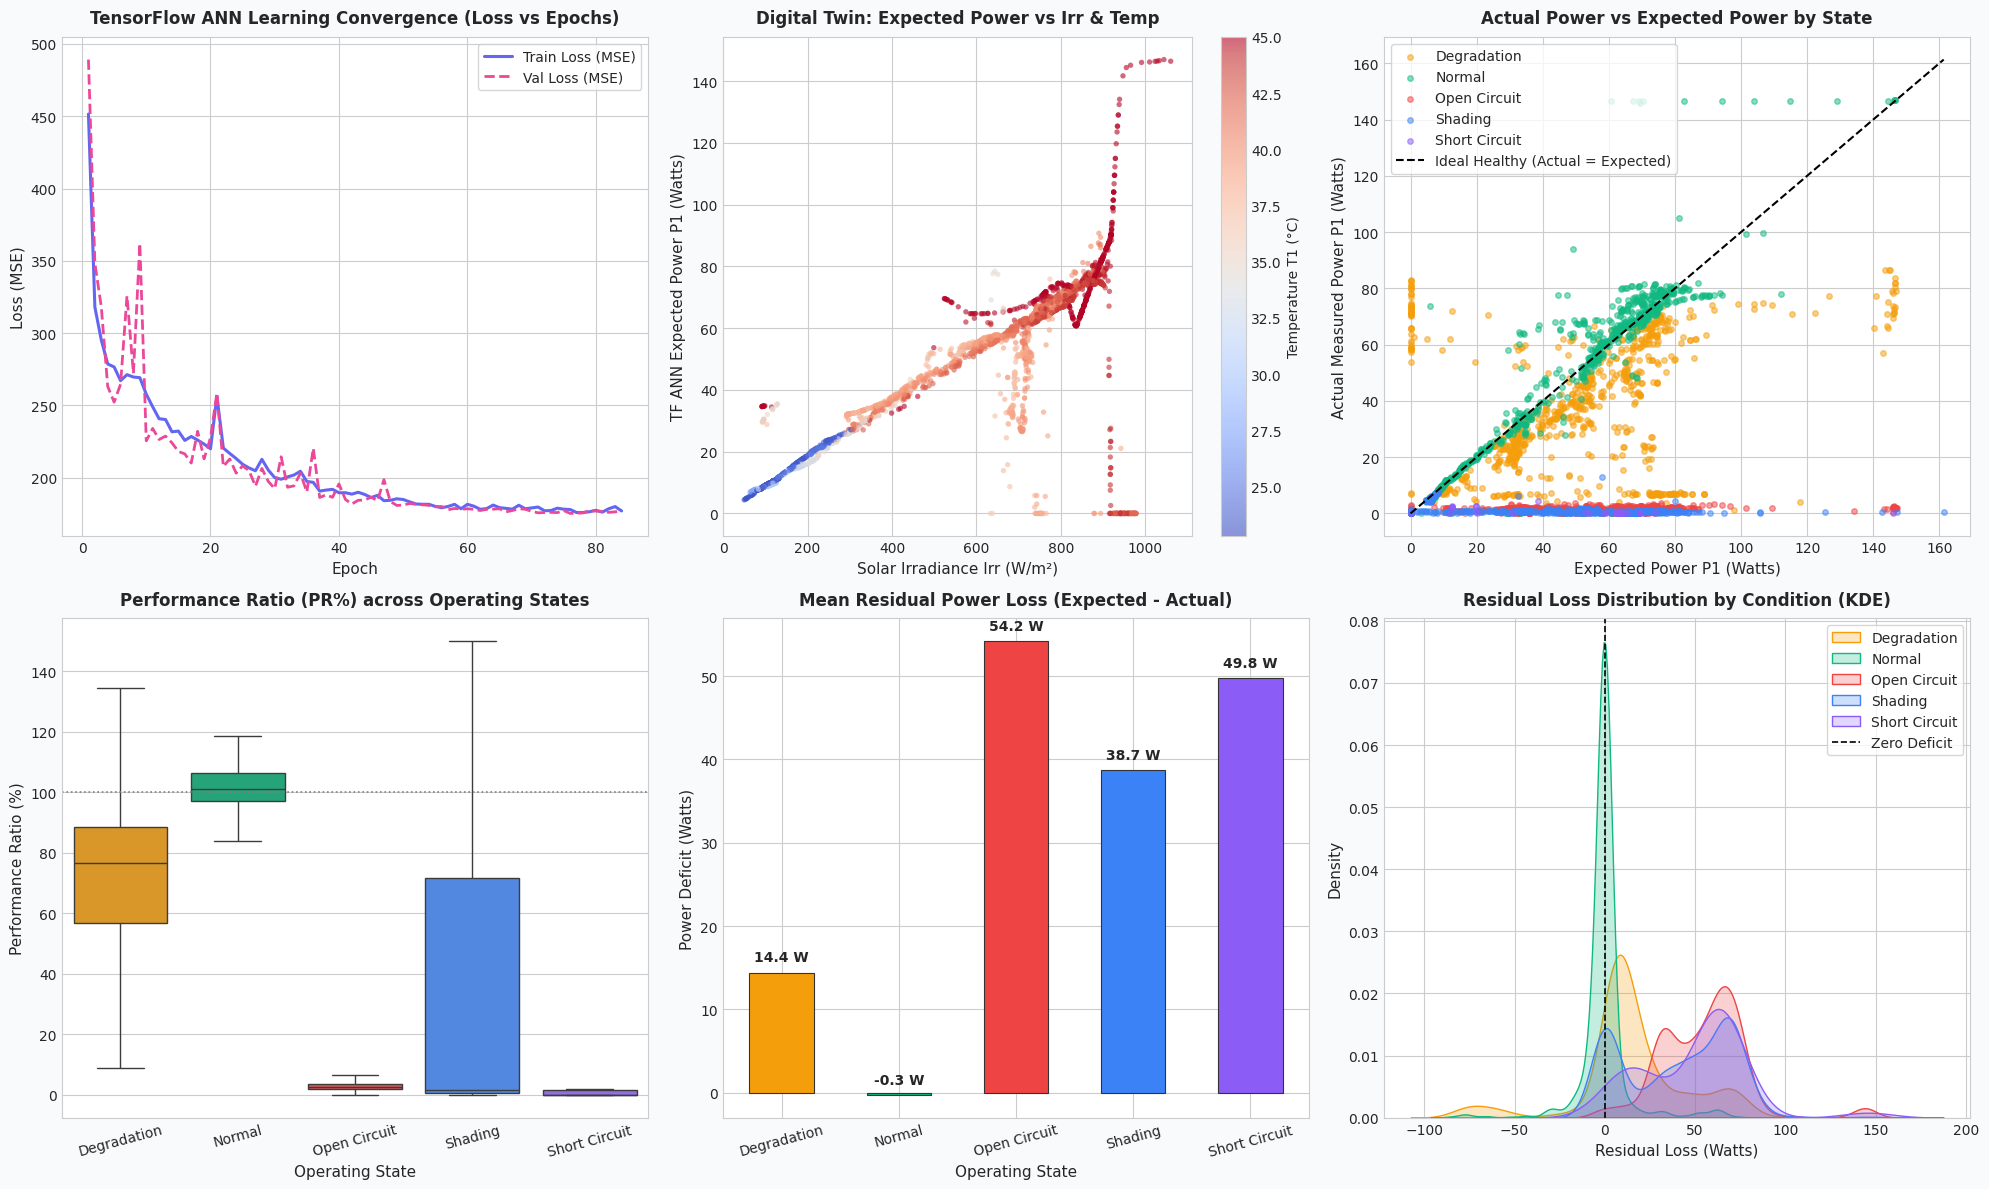

In [7]:
def generate_visualizations(model, history, test_combined_df: pd.DataFrame, save_dir: str = "images"):
    """
    Generates plots illustrating TF ANN Convergence, Expected Power, Actual vs Expected, and Residual Fault Analysis.
    """
    Path(save_dir).mkdir(parents=True, exist_ok=True)
    
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.patch.set_facecolor('#f8fafc')
    
    palette = {
        'Normal': '#10b981',       # Green
        'Degradation': '#f59e0b',  # Amber
        'Shading': '#3b82f6',      # Blue
        'Open Circuit': '#ef4444', # Red
        'Short Circuit': '#8b5cf6' # Purple
    }
    
    # 1. TensorFlow Learning Curves
    ax_loss = axes[0, 0]
    epochs_range = range(1, len(history.history['loss']) + 1)
    ax_loss.plot(epochs_range, history.history['loss'], color='#6366f1', lw=2.2, label='Train Loss (MSE)')
    ax_loss.plot(epochs_range, history.history['val_loss'], color='#ec4899', lw=2.0, linestyle='--', label='Val Loss (MSE)')
    ax_loss.set_title('TensorFlow ANN Learning Convergence (Loss vs Epochs)', fontsize=12, fontweight='bold', pad=10)
    ax_loss.set_xlabel('Epoch', fontsize=11)
    ax_loss.set_ylabel('Loss (MSE)', fontsize=11)
    ax_loss.legend(frameon=True, facecolor='#ffffff')
    ax_loss.set_facecolor('#ffffff')
    
    # 2. Expected Power vs Irradiance, colored by Temperature
    ax1 = axes[0, 1]
    sample_normal = test_combined_df[test_combined_df['Label_S1'] == 'Normal'].sample(n=min(3000, len(test_combined_df)), random_state=42)
    scatter1 = ax1.scatter(
        sample_normal['Irr'], sample_normal['P1_expected'],
        c=sample_normal['T1'], cmap='coolwarm', alpha=0.6, s=15, edgecolors='none'
    )
    cbar1 = plt.colorbar(scatter1, ax=ax1)
    cbar1.set_label('Temperature T1 (°C)', fontsize=10)
    ax1.set_title('Digital Twin: Expected Power vs Irr & Temp', fontsize=12, fontweight='bold', pad=10)
    ax1.set_xlabel('Solar Irradiance Irr (W/m²)', fontsize=11)
    ax1.set_ylabel('TF ANN Expected Power P1 (Watts)', fontsize=11)
    ax1.set_facecolor('#ffffff')

    # 3. Actual vs Expected Power Scatter
    ax2 = axes[0, 2]
    sample_indices = test_combined_df.groupby('Label_S1').apply(
        lambda g: g.sample(min(len(g), 800), random_state=42).index
    ).explode().values
    sample_vis = test_combined_df.loc[sample_indices].copy()
    
    for label, group in sample_vis.groupby('Label_S1'):
        ax2.scatter(
            group['P1_expected'], group['P1'],
            label=label, alpha=0.5, s=16, color=palette.get(label, '#6b7280')
        )
    max_val = max(sample_vis['P1_expected'].max(), sample_vis['P1'].max())
    ax2.plot([0, max_val], [0, max_val], 'k--', lw=1.5, label='Ideal Healthy (Actual = Expected)')
    ax2.set_title('Actual Power vs Expected Power by State', fontsize=12, fontweight='bold', pad=10)
    ax2.set_xlabel('Expected Power P1 (Watts)', fontsize=11)
    ax2.set_ylabel('Actual Measured Power P1 (Watts)', fontsize=11)
    ax2.legend(frameon=True, facecolor='#ffffff')
    ax2.set_facecolor('#ffffff')

    # 4. Performance Ratio Boxplot
    ax3 = axes[1, 0]
    sns.boxplot(
        data=sample_vis, x='Label_S1', y='PR%', hue='Label_S1',
        palette=palette, ax=ax3, showfliers=False, legend=False
    )
    ax3.axhline(100, color='gray', linestyle=':', lw=1.2, label='100% PR Reference')
    ax3.set_title('Performance Ratio (PR%) across Operating States', fontsize=12, fontweight='bold', pad=10)
    ax3.set_xlabel('Operating State', fontsize=11)
    ax3.set_ylabel('Performance Ratio (%)', fontsize=11)
    ax3.tick_params(axis='x', rotation=15)
    ax3.set_facecolor('#ffffff')

    # 5. Residual Loss Barplot
    ax4 = axes[1, 1]
    res_summary = test_combined_df.groupby('Label_S1')['Residual_Loss'].mean().reset_index()
    bars = ax4.bar(
        res_summary['Label_S1'], res_summary['Residual_Loss'],
        color=[palette.get(l, '#6b7280') for l in res_summary['Label_S1']],
        edgecolor='#333333', linewidth=0.8, width=0.55
    )
    for bar in bars:
        h = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width() / 2, h + 1.0, f"{h:.1f} W", ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax4.set_title('Mean Residual Power Loss (Expected - Actual)', fontsize=12, fontweight='bold', pad=10)
    ax4.set_xlabel('Operating State', fontsize=11)
    ax4.set_ylabel('Power Deficit (Watts)', fontsize=11)
    ax4.tick_params(axis='x', rotation=15)
    ax4.set_facecolor('#ffffff')

    # 6. Residual Loss Distribution (KDE)
    ax5 = axes[1, 2]
    for label, group in sample_vis.groupby('Label_S1'):
        sns.kdeplot(group['Residual_Loss'], ax=ax5, label=label, color=palette.get(label, '#6b7280'), fill=True, alpha=0.25)
    ax5.axvline(0, color='black', linestyle='--', lw=1.2, label='Zero Deficit')
    ax5.set_title('Residual Loss Distribution by Condition (KDE)', fontsize=12, fontweight='bold', pad=10)
    ax5.set_xlabel('Residual Loss (Watts)', fontsize=11)
    ax5.set_ylabel('Density', fontsize=11)
    ax5.legend(frameon=True, facecolor='#ffffff')
    ax5.set_facecolor('#ffffff')

    plt.tight_layout()
    plot_file = os.path.join(save_dir, "panel1_tensorflow_ann_expected_power_analysis.png")
    plt.savefig(plot_file, dpi=200, bbox_inches='tight')
    print(f"Visualization figure saved to: {plot_file}")
    plt.show()
    return plot_file

plot_path = generate_visualizations(tf_model, history, evaluated_df)
